# Quantum Simulation of Quantum Teleportation Using Qiskit

## 1. Project Overview

Quantum teleportation is a quantum information protocol that transfers an unknown quantum state from one qubit to another using shared entanglement and classical communication.

Despite its name, quantum teleportation does not transport matter or allow information to travel faster than light. The protocol requires a shared entangled pair, a joint measurement, and classical communication of the measurement result.

In this project, I simulate the quantum teleportation protocol using Python and Qiskit. I prepare an input quantum state, create an entangled Bell pair, simulate Alice's measurement and Bob's conditional correction operations, and investigate whether the protocol successfully transfers the state.

### Objectives

* Understand the mathematical principles behind quantum teleportation.
* Prepare an arbitrary single-qubit input state.
* Construct a Bell pair using quantum gates.
* Implement Alice's measurement operations and Bob's conditional corrections.
* Simulate the protocol using Qiskit.
* Verify the transferred state using quantum-state fidelity.

### Tools

Python, NumPy, Matplotlib, Qiskit, and Qiskit Aer.

### Scope

This is an educational simulation using an ideal quantum circuit simulator. It does not involve a physical quantum computer or experimental transmission of quantum states.

In [1]:
%pip install -q qiskit qiskit-aer numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.5 MB/s eta 0:00:00


## 2. Mathematical Background

### 2.1 A single-qubit state

A general pure qubit state can be written as

$$
|\psi\rangle=\alpha|0\rangle+\beta|1\rangle,
$$

where \(\alpha\) and \(\beta\) are complex probability amplitudes satisfying

$$
|\alpha|^2+|\beta|^2=1.
$$

For this project, the input state is parameterized as

$$
|\psi\rangle=
\cos\left(\frac{\theta}{2}\right)|0\rangle+
e^{i\phi}\sin\left(\frac{\theta}{2}\right)|1\rangle.
$$

The parameters \(\theta\) and \(\phi\) determine the state.

### 2.2 Bell-pair entanglement

Alice and Bob share one qubit each from the Bell state

$$
|\Phi^+\rangle=
\frac{|00\rangle+|11\rangle}{\sqrt{2}}.
$$

This state is created by applying a Hadamard gate to one qubit followed by a controlled-NOT (CNOT) gate.

### 2.3 Teleportation protocol

The protocol uses three qubits:

* Qubit 0: Alice's original input state.
* Qubit 1: Alice's half of the entangled Bell pair.
* Qubit 2: Bob's half of the Bell pair.

Alice applies a CNOT gate and a Hadamard gate to her two qubits, then measures them. She communicates the two classical measurement bits to Bob. Bob applies the corresponding Pauli corrections to recover the input state.

The original qubit is not copied. Alice's measurement consumes the original quantum state, while the protocol allows Bob's qubit to recover that state after the required classical information is received.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector

# Parameters defining the input state
theta = np.pi / 3
phi = np.pi / 4

# |psi> = alpha|0> + beta|1>
input_state = np.array([
    np.cos(theta / 2),
    np.exp(1j * phi) * np.sin(theta / 2)
], dtype=complex)

print("Input state amplitudes:")
print(input_state)

print("\nInput-state probabilities:")
print(np.abs(input_state) ** 2)

print("\nNormalization check:")
print(np.isclose(np.sum(np.abs(input_state) ** 2), 1.0))

Input state amplitudes:
[0.8660254 +0.j         0.35355339+0.35355339j]

Input-state probabilities:
[0.75 0.25]

Normalization check:
True


## 3. Quantum Circuit Construction

The circuit follows the standard quantum teleportation protocol.

### Step 1: Prepare the input state

Alice prepares the state to be transferred on qubit 0.

### Step 2: Create the Bell pair

A Hadamard gate and a CNOT gate entangle qubits 1 and 2. Alice keeps qubit 1, while Bob holds qubit 2.

### Step 3: Perform Alice's operations

Alice applies a CNOT gate from qubit 0 to qubit 1, followed by a Hadamard gate on qubit 0.

### Step 4: Measure Alice's qubits

Alice measures qubits 0 and 1. These measurements produce two classical bits.

### Step 5: Apply Bob's corrections

Bob uses the classical measurement results to determine whether to apply an X gate, a Z gate, both, or neither. These corrections recover the original input state on Bob's qubit in the ideal protocol.

In [3]:
q = QuantumRegister(3, "q")
c = ClassicalRegister(2, "c")

qc = QuantumCircuit(q, c)

# Step 1: Prepare Alice's input state
qc.initialize(input_state, q[0])

# Step 2: Create an entangled Bell pair
qc.h(q[1])
qc.cx(q[1], q[2])

# Step 3: Alice's Bell-basis operations
qc.cx(q[0], q[1])
qc.h(q[0])

# Step 4: Alice measures her two qubits
qc.measure(q[0], c[0])
qc.measure(q[1], c[1])

# Step 5: Bob applies corrections.
# Qiskit displays the classical register as c[1]c[0].
with qc.if_test((c, 1)):
    qc.z(q[2])

with qc.if_test((c, 2)):
    qc.x(q[2])

with qc.if_test((c, 3)):
    qc.x(q[2])
    qc.z(q[2])

print(qc.draw(output="text"))

     ┌──────────────────────────────────────┐          ┌───┐┌─┐             »
q_0: ┤ Initialize(0.86603,0.35355+0.35355j) ├───────■──┤ H ├┤M├─────────────»
     └────────────────┬───┬─────────────────┘     ┌─┴─┐└┬─┬┘└╥┘             »
q_1: ─────────────────┤ H ├────────────────────■──┤ X ├─┤M├──╫──────────────»
                      └───┘                  ┌─┴─┐└───┘ └╥┘  ║ ┌────── ┌───┐»
q_2: ────────────────────────────────────────┤ X ├───────╫───╫─┤ If-0  ┤ Z ├»
                                             └───┘       ║   ║ └──╥─── └───┘»
                                                         ║   ║ ┌──╨──┐      »
c: 2/════════════════════════════════════════════════════╩═══╩═╡ 0x1 ╞══════»
                                                         1   0 └─────┘      »
«                                                                  
«q_0: ─────────────────────────────────────────────────────────────
«                                                                  
«q_1: ──────────

## 4. Measurement Experiment

The circuit is executed repeatedly on an ideal quantum simulator.

Each run produces a measurement result for Alice's two qubits. For a general input state, the four possible results occur with probabilities determined by the teleportation protocol. In the ideal case, these results are approximately equally frequent over many shots.

The measurement counts show the classical communication outcomes. They do not, by themselves, establish that Bob's state has been correctly reconstructed; this is checked separately using state fidelity.

In [4]:
simulator = AerSimulator()
shots = 5000

result = simulator.run(
    qc,
    shots=shots,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement counts:")
print(counts)

print("\nTotal shots:", sum(counts.values()))

Measurement counts:
{'11': 1217, '00': 1248, '10': 1291, '01': 1244}

Total shots: 5000


## 5. Visualization of Measurement Outcomes

A bar graph helps compare the frequencies of Alice's four possible classical outcomes. The outcomes are `00`, `01`, `10`, and `11`.

The graph provides a visual summary of the measurement experiment. Small differences between the bars are expected because the simulator samples a finite number of shots.

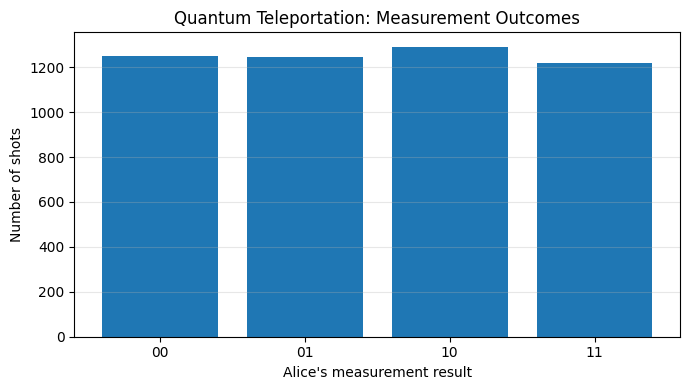

In [5]:
outcomes = ["00", "01", "10", "11"]
frequencies = [counts.get(outcome, 0) for outcome in outcomes]

plt.figure(figsize=(7, 4))
plt.bar(outcomes, frequencies)

plt.xlabel("Alice's measurement result")
plt.ylabel("Number of shots")
plt.title("Quantum Teleportation: Measurement Outcomes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("quantum_teleportation_counts.png", dpi=300)
plt.show()

## 6. State Verification Using Fidelity

Measurement counts alone cannot verify successful teleportation. To test the protocol, we compare Bob's final quantum state with Alice's original input state.

For two pure states, fidelity is

$$
F=|\langle\psi|\phi\rangle|^2.
$$

A fidelity of 1 means the states are identical, while a value below 1 indicates a difference.

We use a separate circuit without measurements and without classical correction conditions. Instead, we explicitly simulate each possible measurement branch, apply the corresponding correction to Bob's qubit, and combine the resulting reduced states according to their probabilities. This lets us calculate Bob's final density matrix and compare it with the original input state.

This verification is performed in a simulator, not on physical hardware.

In [6]:
from qiskit.quantum_info import DensityMatrix, partial_trace, state_fidelity

# Recreate the protocol before Alice's measurements
base = QuantumCircuit(3)
base.initialize(input_state, 0)
base.h(1)
base.cx(1, 2)
base.cx(0, 1)
base.h(0)

# Get the statevector before measurement
full_state = Statevector.from_instruction(base)

# Calculate Bob's reduced state for each possible Alice outcome
bob_density = np.zeros((2, 2), dtype=complex)
branch_probabilities = {}

for outcome in range(4):
    # Project onto the outcome for qubits 0 and 1.
    # Qubit 0 corresponds to the least-significant bit.
    bit0 = outcome & 1
    bit1 = (outcome >> 1) & 1

    projected = np.zeros(8, dtype=complex)

    for index, amplitude in enumerate(full_state.data):
        if (index & 1) == bit0 and ((index >> 1) & 1) == bit1:
            projected[index] = amplitude

    probability = np.vdot(projected, projected).real
    branch_probabilities[f"{bit1}{bit0}"] = probability

    if probability < 1e-12:
        continue

    # Normalize the post-measurement branch
    projected /= np.sqrt(probability)
    branch_state = Statevector(projected)

    # Apply corrections matching the circuit's bit mapping
    correction = QuantumCircuit(3)

    if outcome == 1:
        correction.z(2)
    elif outcome == 2:
        correction.x(2)
    elif outcome == 3:
        correction.x(2)
        correction.z(2)

    corrected_state = branch_state.evolve(correction)

    # Trace out qubits 0 and 1, keeping Bob's qubit 2
    bob_branch = partial_trace(
        DensityMatrix(corrected_state),
        [0, 1]
    )

    bob_density += probability * bob_branch.data

print("Alice's outcome probabilities:")
print(branch_probabilities)

print("\nBob's final density matrix:")
print(bob_density)

target_density = DensityMatrix(input_state)
fidelity = state_fidelity(DensityMatrix(bob_density), target_density)

print("\nTeleportation fidelity:", fidelity)
print("Successful ideal-state recovery:", np.isclose(fidelity, 1.0))

Alice's outcome probabilities:
{'00': np.float64(0.24999999999999986), '01': np.float64(0.24999999999999986), '10': np.float64(0.24999999999999986), '11': np.float64(0.24999999999999986)}

Bob's final density matrix:
[[0.75      +0.00000000e+00j 0.30618622-3.06186218e-01j]
 [0.30618622+3.06186218e-01j 0.25      -8.96010176e-18j]]

Teleportation fidelity: 0.9999999999999998
Successful ideal-state recovery: True


## 7. Results and Discussion

The simulation implements the quantum teleportation protocol using three qubits.

Alice prepares an input state and shares an entangled Bell pair with Bob. She then performs the required two-qubit operations and measures her qubits. Bob's correction operations depend on the classical measurement result.

The measurement histogram summarizes the four possible outcomes. The fidelity calculation provides a more direct test of whether Bob's final state matches the original input state.

For the ideal circuit, the fidelity is expected to be approximately 1. This demonstrates successful state transfer within the simulation.

The experiment illustrates how entanglement and classical communication work together in quantum teleportation. It does not imply faster-than-light communication or the copying of an unknown quantum state.

## 8. Conclusion

This project simulated quantum teleportation using Qiskit. It demonstrated the preparation of an input state, the creation of an entangled Bell pair, Alice's measurement operations, and Bob's conditional corrections.

The fidelity calculation connected the circuit operations to a quantitative measure of state recovery. The project provides a foundation for further study of quantum information protocols.

## 9. Limitations and Future Work

This project uses an ideal simulator rather than physical quantum hardware. It therefore does not reproduce the gate errors, decoherence, or measurement noise present in real devices.

Possible extensions include:

* Testing multiple input states by varying \(\theta\) and \(\phi\).
* Simulating noise and comparing fidelity with the ideal result.
* Studying the effects of different quantum channels.
* Exploring quantum error correction as a separate project.

The results should be interpreted as a simulation-based demonstration, not as an experimental quantum communication system.